# Big Data Analytics: Project 1
## From 2,000 social-media records to a marketing decision

**Dataset:** `mrudukp/social-media-sentiment-analysis` (2,260 rows, 13 columns), used to teach the *workflow*.
**Caveat:** this data is **not verified** as coming from Pakistani clothing brands, and the repository has no LICENSE file.
Do not make claims about Pakistan from it. Use an authorised export or clearly labelled synthetic data for that.

Run the cells top to bottom (Colab: *Runtime > Run all*).

## Step 3-4. Load the data and inspect it before assuming anything

In [ ]:
import os, time, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
sns.set_theme(style="whitegrid")

FILE = "social_media_sentiment_raw.csv"
URL = "https://raw.githubusercontent.com/mrudukp/social-media-sentiment-analysis/main/" + FILE
if not os.path.exists(FILE):
    try:
        pd.read_csv(URL).to_csv(FILE, index=False)      # download once
    except Exception:
        from google.colab import files                  # fallback: upload by hand
        files.upload()
raw = pd.read_csv(FILE)
raw.to_csv("backup_original.csv", index=False)           # keep an untouched copy
print(raw.shape)
raw.head()

(2260, 13)


,post_id,timestamp,platform,user,followers_count,verified,text,hashtags,country,likes,retweets_shares,comments,sentiment
0,P100040,2023-02-10 13:01:38,TikTok,quinn_5984,668.0,No,"Reading more about service this week, lots to ...",#Travel,USA,30,8,4.0,Neutral
1,P101934,2024-04-26 19:26:56,Facebook,taylor_6536,54.0,No,This event launch exceeded all my expectations...,NaN,Canada,19,1,1.0,Positive
2,P100375,2023-06-29 17:51:22,Instagram,ravi_5073,559.0,No,Worst brand experience I've had in a long time...,#Art,UK,27,8,1.0,Negative
3,P101166,2023-02-25 03:21:56,Instagram,avery_3025,3123.0,No,"Not happy at all about the app changes, feels ...",#Climate #Movies #Fitness,UAE,43,7,1.0,Negative
4,P100607,2023-03-03 10:20:26,LinkedIn,avery_2800,549.0,Yes,This product launch exceeded all my expectatio...,NaN,India,33,3,1.0,Positive


## Step 5. Data objects and attributes
**One row = one social-media post** (not a user, comment, or campaign).

| Type | Columns |
|---|---|
| Numerical | `likes`, `retweets_shares`, `comments`, `followers_count` |
| Categorical | `platform`, `country`, `verified`, `sentiment` |
| Text | `text`, `hashtags`, `user` |
| Date/time | `timestamp` |

In [ ]:
print("Rows, columns:", raw.shape)
display(raw.dtypes)
display(raw.isna().sum())
print("Exact duplicate rows:", raw.duplicated().sum())
print("Repeated post_id    :", raw["post_id"].duplicated().sum())
print("Negative likes      :", (raw["likes"] < 0).sum())
print("Platform spellings  :", raw["platform"].unique())
display(raw.describe(include="all").T)

Rows, columns: (2260, 13)


,0
post_id,object
timestamp,object
platform,object
user,object
followers_count,object
verified,object
text,object
hashtags,object
country,object
likes,int64


,0
post_id,0
timestamp,0
platform,0
user,0
followers_count,90
verified,44
text,0
hashtags,788
country,126
likes,0


Exact duplicate rows: 44
Repeated post_id    : 60
Negative likes      : 8
Platform spellings  : ['TikTok' 'Facebook' 'Instagram' 'LinkedIn' 'Twitter' 'TWITTER'
 'INSTAGRAM' 'FACEBOOK' 'LINKEDIN' 'TIKTOK']


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
post_id,2260,2200,P100054,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
timestamp,2260,2200,2023-08-13 06:24:13,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
platform,2260,10,Twitter,691,NaN,NaN,NaN,NaN,NaN,NaN,NaN
user,2260,2185,liam_2262,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
followers_count,2170,1814,410.0,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
verified,2216,2,No,2024,NaN,NaN,NaN,NaN,NaN,NaN,NaN
text,2260,150,"Best app experience ever, highly recommend to ...",27,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hashtags,1472,662,#Health,53,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,2134,24,USA,433,NaN,NaN,NaN,NaN,NaN,NaN,NaN
likes,2260.0,NaN,NaN,NaN,35.94646,16.56231,-1.0,25.0,33.0,44.0,126.0


### Data dictionary and what missing means
* `hashtags` blank = **no hashtags** (a real zero), not an error.
* `comments` blank = **not collected**. Do not turn it into 0.
* `likes < 0` is **invalid**, so set it to missing (we don't know the true value).
* `followers_count` was stored as text with commas (`"1,182"`).
* `TWITTER` vs `Twitter`, and `"usa  "` vs `USA`, are the same value written differently.

In [ ]:
dd = pd.DataFrame([
 ("post_id","identifier","one post (the observational unit)"),
 ("timestamp","date/time","when posted"),
 ("platform","categorical","Twitter, Instagram, Facebook, TikTok, LinkedIn"),
 ("user","text/id","anonymised handle"),
 ("followers_count","numerical","author's followers"),
 ("verified","categorical","Yes / No"),
 ("text","text","post content (templated sentences)"),
 ("hashtags","text","blank = none"),
 ("country","categorical","author's country"),
 ("likes","numerical","negative = invalid"),
 ("retweets_shares","numerical","shares / retweets"),
 ("comments","numerical","blank = not collected"),
 ("sentiment","categorical","Positive / Neutral / Negative")],
 columns=["column","type","meaning"])
dd

,column,type,meaning
0,post_id,identifier,one post (the observational unit)
1,timestamp,date/time,when posted
2,platform,categorical,"Twitter, Instagram, Facebook, TikTok, LinkedIn"
3,user,text/id,anonymised handle
4,followers_count,numerical,author's followers
5,verified,categorical,Yes / No
6,text,text,post content (templated sentences)
7,hashtags,text,blank = none
8,country,categorical,author's country
9,likes,numerical,negative = invalid


## Cleaning (documented, reversible, never silent)

In [ ]:
df = raw.copy()
for c in ["platform","country","verified","sentiment","user","hashtags"]:
    df[c] = df[c].astype("string").str.strip()
df["platform"] = df["platform"].str.title().replace({"Tiktok":"TikTok","Linkedin":"LinkedIn"})
df["country"]  = df["country"].str.title().replace({"Usa":"USA","Uk":"UK","Uae":"UAE"})
df["followers_count"] = pd.to_numeric(df["followers_count"].astype("string").str.replace(",","",regex=False), errors="coerce")
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
df.loc[df["likes"] < 0, "likes"] = np.nan                 # invalid -> missing, not zero

n0 = len(df)
df = df.drop_duplicates().drop_duplicates(subset="post_id", keep="first").reset_index(drop=True)
print(f"Removed {n0-len(df)} duplicate posts ({n0} -> {len(df)}).")
print("Note: only 44 were exact duplicates in the RAW file. Standardising case/commas revealed 16 more.")

df["hashtag_count"]    = df["hashtags"].fillna("").str.count("#")
df["total_engagement"] = df[["likes","retweets_shares","comments"]].sum(axis=1, min_count=3)
df["hour"]  = df["timestamp"].dt.hour
df["month"] = df["timestamp"].dt.to_period("M").dt.to_timestamp()
df.isna().sum()

Removed 60 duplicate posts (2260 -> 2200).
Note: only 44 were exact duplicates in the RAW file. Standardising case/commas revealed 16 more.


,0
post_id,0
timestamp,0
platform,0
user,0
followers_count,88
verified,44
text,0
hashtags,762
country,66
likes,8


## Step 6. EDA: turn columns into questions
1. Which platforms are most represented?
2. What do mean and median say about typical engagement, and do a few posts dominate?
3. Do likes and comments move together?
4. Does engagement differ by platform and by sentiment?

In [ ]:
display(df["platform"].value_counts())
g = df.groupby("platform").agg(n=("post_id","size"),
        likes_mean=("likes","mean"), likes_median=("likes","median"),
        comments_median=("comments","median"),
        engagement_median=("total_engagement","median")).round(1).sort_values("engagement_median", ascending=False)
g

,count
platform,
Twitter,726
Instagram,595
TikTok,390
Facebook,370
LinkedIn,119


,n,likes_mean,likes_median,comments_median,engagement_median
platform,,,,,
TikTok,390,47.3,44.0,4.0,56.0
Instagram,595,39.0,37.0,3.0,46.0
Twitter,726,34.0,32.0,3.0,40.0
Facebook,370,28.3,26.0,2.0,34.0
LinkedIn,119,21.2,20.0,2.0,24.5


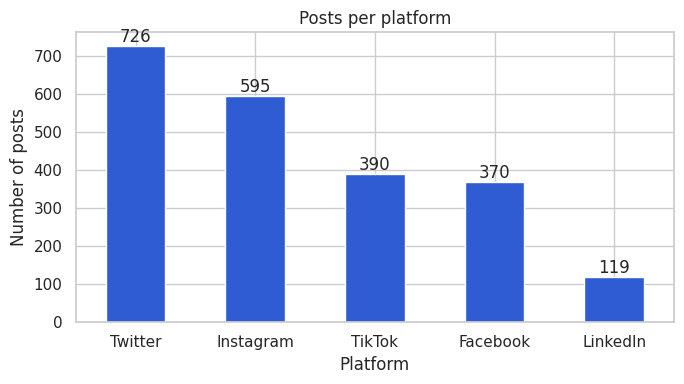

In [ ]:
# Chart 1: posts per platform  (always show n!)
pc = df["platform"].value_counts()
ax = pc.plot(kind="bar", color="#2f5bd3", figsize=(7,4))
ax.bar_label(ax.containers[0])
plt.title("Posts per platform"); plt.xlabel("Platform"); plt.ylabel("Number of posts")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

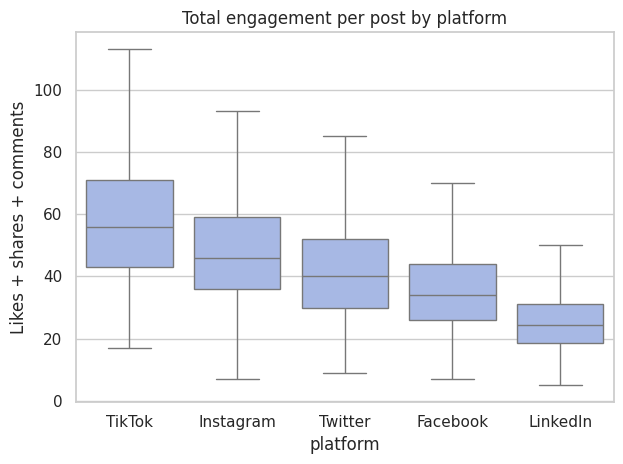

Kruskal-Wallis across platforms: H=419.5, p=1.7e-89


In [ ]:
# Chart 2: engagement distribution by platform
order = g.index
sns.boxplot(data=df, x="platform", y="total_engagement", order=order, color="#9db4ee", showfliers=False)
plt.title("Total engagement per post by platform"); plt.ylabel("Likes + shares + comments")
plt.tight_layout(); plt.show()

H, p = stats.kruskal(*[x["total_engagement"].dropna() for _, x in df.groupby("platform")])
print(f"Kruskal-Wallis across platforms: H={H:.1f}, p={p:.2g}")

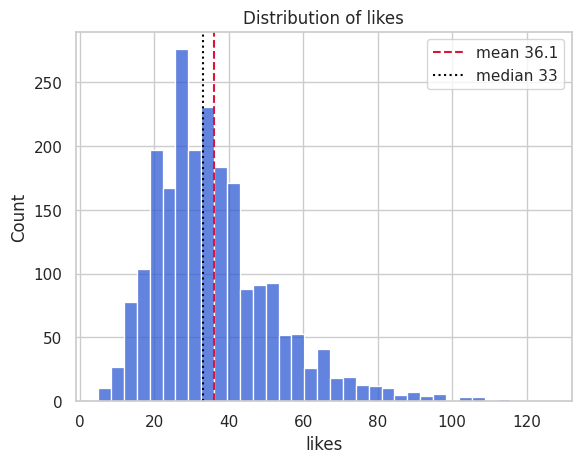

Mean 36.1 vs median 33; skew 1.32; top 10% of posts = 20.6% of all engagement


In [ ]:
# Chart 3: are a few posts dominating the mean?
likes = df["likes"].dropna()
sns.histplot(likes, bins=35, color="#2f5bd3")
plt.axvline(likes.mean(), color="crimson", ls="--", label=f"mean {likes.mean():.1f}")
plt.axvline(likes.median(), color="black", ls=":", label=f"median {likes.median():.0f}")
plt.legend(); plt.title("Distribution of likes"); plt.show()
top = df.nlargest(int(len(df)*0.10), "total_engagement")["total_engagement"].sum() / df["total_engagement"].sum()
print(f"Mean {likes.mean():.1f} vs median {likes.median():.0f}; skew {stats.skew(likes):.2f}; top 10% of posts = {top:.1%} of all engagement")

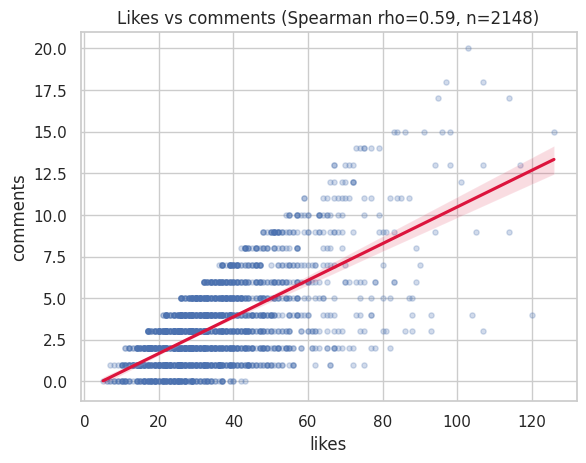

In [ ]:
# Chart 4: likes vs comments
sub = df[["likes","comments"]].dropna()
rho = stats.spearmanr(sub["likes"], sub["comments"])
sns.regplot(data=sub, x="likes", y="comments", scatter_kws={"alpha":.25,"s":14}, line_kws={"color":"crimson"})
plt.title(f"Likes vs comments (Spearman rho={rho.statistic:.2f}, n={len(sub)})"); plt.show()

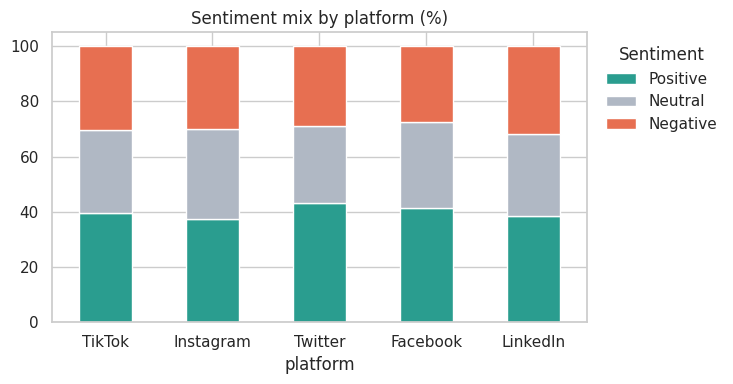

,size,median,mean
sentiment,,,
Negative,636,40.0,43.0
Neutral,652,35.0,38.6
Positive,879,50.0,54.0


In [ ]:
# Chart 5: sentiment mix by platform, and engagement by sentiment
sent = df.dropna(subset=["sentiment"])
ct = (pd.crosstab(sent["platform"], sent["sentiment"], normalize="index")*100).loc[order]
ax = ct[["Positive","Neutral","Negative"]].plot(kind="bar", stacked=True, figsize=(7.5,4),
                                                color=["#2a9d8f","#b0b8c4","#e76f51"])
ax.legend(title="Sentiment", loc="upper left", bbox_to_anchor=(1.01,1), frameon=False)
plt.title("Sentiment mix by platform (%)"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()
sent.groupby("sentiment")["total_engagement"].agg(["size","median","mean"]).round(1)

## Step 7. Business interpretation (Finding / Evidence / Action / Limitation)

| | |
|---|---|
| **Finding 1** | TikTok posts have the highest typical engagement and LinkedIn the lowest. |
| **Evidence** | Median total engagement: TikTok 56, Instagram 46, Twitter 40, Facebook 34, LinkedIn 24.5 (Kruskal-Wallis p < 0.001). Group sizes: 390 / 595 / 726 / 370 / 119. |
| **Finding 2** | Positive posts get more engagement than neutral or negative ones, and negative posts beat neutral ones. |
| **Evidence** | Median engagement: Positive 50 (n=879), Negative 40 (n=636), Neutral 35 (n=652). |
| **Action** | A brand could test shifting a share of its content budget toward TikTok and positive-tone posts, and compare results on one consistent metric. |
| **Limitation** | The platform/country/brand mix is not verified as Pakistani clothing. There is no reach or impressions column, so this is *engagement per post*, **not** engagement rate or ROI. Differences are descriptive, not causal. |

> "Higher median" is evidence about *this dataset*. Check group sizes before calling anything "best".

## Step 8. Scaling experiment: measure, don't manufacture failure
We repeat the **same** cleaned rows to make bigger files. This is a **scaling experiment, not new real-world evidence**.

In [ ]:
import tempfile, psutil
def run(n):
    reps = -(-n // len(df))
    big = pd.concat([df]*reps, ignore_index=True).iloc[:n]
    path = os.path.join(tempfile.gettempdir(), f"scale_{n}.csv")
    big.to_csv(path, index=False); size = os.path.getsize(path)/1e6
    t=time.perf_counter(); x = pd.read_csv(path); t_load=time.perf_counter()-t
    t=time.perf_counter()
    x.groupby("platform")[["likes","comments"]].mean(); x["text"].str.len().mean()
    x.sort_values("total_engagement", ascending=False).head(10)
    t_an=time.perf_counter()-t
    t=time.perf_counter(); x.drop_duplicates(); t_dd=time.perf_counter()-t
    mem = psutil.Process().memory_info().rss/1e6
    os.remove(path)
    return dict(rows=n, file_mb=round(size,1), load_s=round(t_load,2), analysis_s=round(t_an,2),
                dedupe_s=round(t_dd,2), process_mem_mb=round(mem))
# Colab free tier has ~12 GB RAM; if the last row is too heavy, stop at 200,000 and say so.
scale = pd.DataFrame([run(n) for n in [2_000, 20_000, 200_000, 2_000_000]])
scale

,rows,file_mb,load_s,analysis_s,dedupe_s,process_mem_mb
0,2000,0.4,0.01,0.00,0.00,262
1,20000,3.5,0.04,0.01,0.02,274
2,200000,35.2,0.31,0.10,0.13,370
3,2000000,351.7,3.65,1.49,1.35,831


**How to read it.** On a typical 8 GB machine, pandas loads and analyses 2 million rows of this file in seconds.
There is **no universal row count at which pandas "fails"**. Spark or distributed storage becomes worth investigating when
data volume, processing time, memory limits, or sharing/service requirements actually justify it, not for a 2,000-row file.

## Step 9. Preview of classification, clustering and regression (conceptual demo)
Rules used to avoid mistakes: **train/test split**, **no target-derived features** (the engagement columns are never used
to predict engagement), and **scale before clustering**.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, r2_score, mean_absolute_error

feat_num, feat_cat = ["followers_count","hashtag_count","hour"], ["platform","verified","sentiment"]
ml = df.dropna(subset=["likes","retweets_shares","comments"]).copy()
for c in feat_cat: ml[c] = ml[c].astype(object).where(ml[c].notna(), np.nan)
pre = ColumnTransformer([
  ("n", Pipeline([("i",SimpleImputer(strategy="median")),("s",StandardScaler())]), feat_num),
  ("c", Pipeline([("i",SimpleImputer(strategy="constant",fill_value="Unknown")),("o",OneHotEncoder(handle_unknown="ignore"))]), feat_cat)])

# Classification: high vs low engagement
cut = ml["total_engagement"].median(); y = (ml["total_engagement"] > cut).astype(int)
Xtr,Xte,ytr,yte = train_test_split(ml[feat_num+feat_cat], y, test_size=.25, random_state=42, stratify=y)
clf = Pipeline([("p",pre),("m",RandomForestClassifier(300,random_state=42))]).fit(Xtr,ytr); p = clf.predict(Xte)
print(f"Classification  accuracy={accuracy_score(yte,p):.2f}  F1={f1_score(yte,p):.2f}  (majority-class baseline={max(yte.mean(),1-yte.mean()):.2f})")

# Regression: predict likes
Xtr,Xte,ytr,yte = train_test_split(ml[feat_num+feat_cat], ml["likes"], test_size=.25, random_state=42)
reg = Pipeline([("p",pre),("m",RandomForestRegressor(300,random_state=42))]).fit(Xtr,ytr); pr = reg.predict(Xte)
print(f"Regression      R2={r2_score(yte,pr):.2f}  MAE={mean_absolute_error(yte,pr):.1f} likes  (always-predict-median MAE={mean_absolute_error(yte,[ytr.median()]*len(yte)):.1f})")

# Clustering: scaled engagement metrics, no label involved
Z = StandardScaler().fit_transform(ml[["likes","retweets_shares","comments"]])
ml["cluster"] = KMeans(3, n_init=10, random_state=42).fit_predict(Z)
ml.groupby("cluster")[["likes","retweets_shares","comments"]].agg("mean").round(1).assign(posts=ml["cluster"].value_counts().sort_index())

Classification  accuracy=0.79  F1=0.78  (majority-class baseline=0.51)
Regression      R2=0.68  MAE=7.1 likes  (always-predict-median MAE=12.1)


,likes,retweets_shares,comments,posts
cluster,,,,
0,70.4,15.1,8.7,194
1,25.8,3.9,1.9,1173
2,42.9,8.6,4.4,781


**Exit question:** which technique would help *your* marketing question, and what evidence would you need?
These models use only 2,200 templated posts. They show the workflow, not production-grade predictions.

## Step 10. Submission checklist
- [x] Dataset source, license/provenance note, data dictionary
- [x] Record count, column types, missing-value and duplicate checks
- [x] At least two summary statistics and two charts
- [x] Two evidence-based observations and one marketing recommendation
- [x] One limitation, and a reason a scalable tool might help at larger scale

*What does the data tell us, what business problem does it reveal, and what should the business do next?*

**Next project:** add genuine or clearly labelled sample paid-campaign data (spend, impressions, clicks, conversions)
before Meta Ads / Google Ads analysis. Organic engagement alone cannot calculate ROAS.